In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


#import


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error, f1_score
import numpy as np
import ast
import matplotlib.dates as mdates

#kospi200 data

In [ ]:
companies = [
    "Hyundai", "Kbfg", "Kia", "Lgchem", "Lgensol", "Naver", "PoscoHoldings",
    "SamsungBiologics", "Samsung", "Skhynix"
]

kospi_path = '/content/drive/MyDrive/dataset/kospi200_cleaned_data.csv'

df_kospi = pd.read_csv(kospi_path)
df_kospi['y'] = df_kospi['y'].astype(str)
df_kospi['m'] = df_kospi['m'].astype(str).str.zfill(2)
df_kospi['d'] = df_kospi['d'].astype(str).str.zfill(2)
df_kospi['date'] = pd.to_datetime(df_kospi['y'] + df_kospi['m'] + df_kospi['d'],format="%Y%m%d")
df_kospi = df_kospi[['date', 'closing price','change']]
df_kospi = df_kospi.sort_values('date').reset_index(drop=True)
df_kospi['target'] = df_kospi['closing price'].shift(-1)
df_kospi.dropna(inplace=True)

df_kospi.head()

,date,closing price,change,target
0,2022-01-27,348.58,-3.39,357.98
1,2022-01-28,357.98,2.70,361.60
2,2022-02-03,361.60,1.01,366.34
3,2022-02-04,366.34,1.31,362.92
4,2022-02-07,362.92,-0.93,363.48


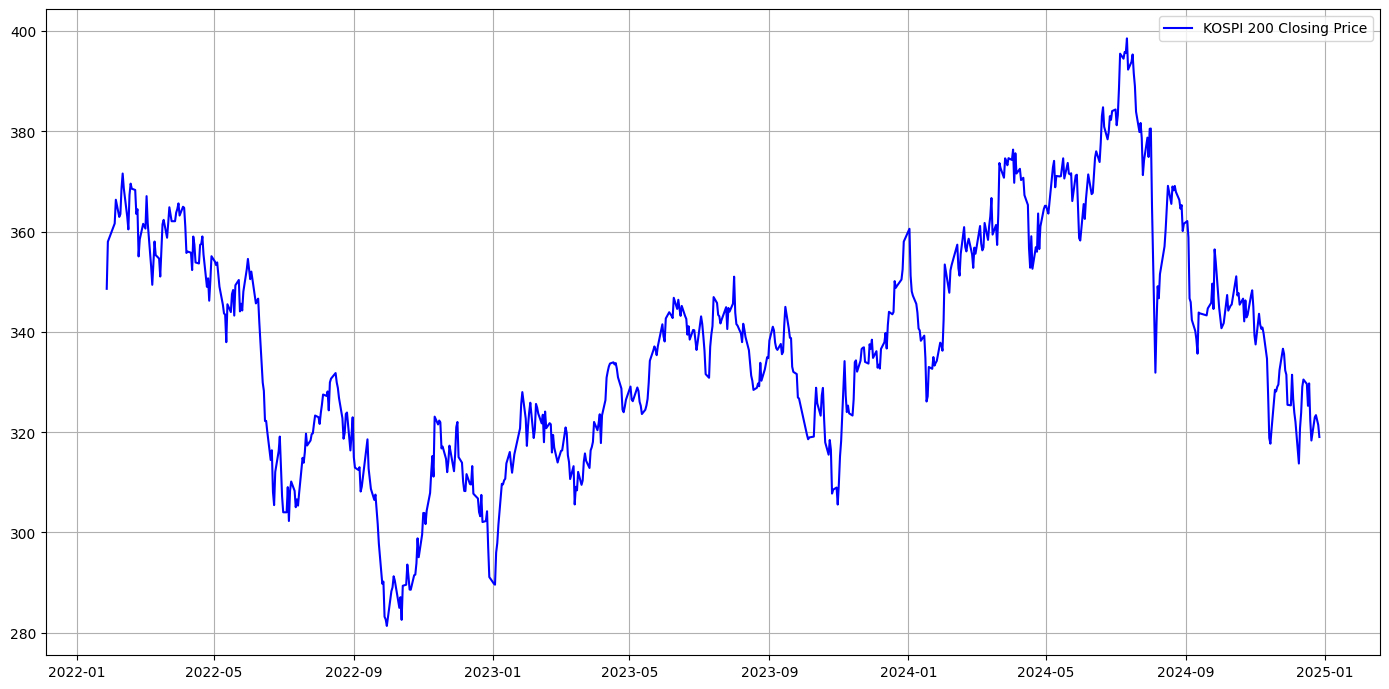

In [ ]:
plt.figure(figsize=(14, 7))
plt.plot(df_kospi['date'], df_kospi['closing price'], label='KOSPI 200 Closing Price', color='blue')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

#json file

orient='records' : dick를 행으로 보고 key값을 열로 확인함

In [ ]:
json_path = '/content/drive/MyDrive/share_drive/박박박사/여러가지_학습후_결과저장/ensemble_model_results.json'
csv_path = '/content/ensemble_model_results.csv'

df = pd.read_json(json_path, orient='records')

df.to_csv(csv_path, index=False, encoding='utf-8-sig')

print(f"CSV 저장 완료: {csv_path}")

CSV 저장 완료: /content/ensemble_model_results.csv


In [ ]:
pd.read_csv(csv_path).head()

,ensemble_name,models_in_ensemble,data_case,cap_method,scaler,time_step,train_ratio,val_ratio,RMSE,MAE,R2,MAPE,F1_Score,y_true,y_pred,dates
0,lstm+gru,"[{'model': 'LSTM', 'model_params': {'units': [...",C,cap_on,minmax,20,0.71,0.151,7.564730,6.065532,0.712624,0.017863,0.608696,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[355.11968994140625, 354.28619384765625, 354.3...","['2024-08-08', '2024-08-09', '2024-08-12', '20..."
1,lstm+gru+cnn,"[{'model': 'LSTM', 'model_params': {'units': [...",C,cap_on,minmax,20,0.71,0.151,7.573782,6.262573,0.711936,0.018336,0.541176,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[354.3024597167969, 353.4403381347656, 353.949...","['2024-08-08', '2024-08-09', '2024-08-12', '20..."
2,lstm+gru,"[{'model': 'LSTM', 'model_params': {'units': [...",A,cap_on,minmax,21,0.71,0.151,7.574497,6.177966,0.711882,0.018000,0.530120,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[356.57574462890625, 355.5582275390625, 354.75...","['2024-08-08', '2024-08-09', '2024-08-12', '20..."
3,lstm+gru,"[{'model': 'LSTM', 'model_params': {'units': [...",C,cap_on,minmax,21,0.71,0.151,7.575380,6.393809,0.711815,0.018661,0.480000,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[352.4490661621094, 351.6785888671875, 351.506...","['2024-08-08', '2024-08-09', '2024-08-12', '20..."
4,lstm,"[{'model': 'LSTM', 'model_params': {'units': [...",C,cap_on,minmax,21,0.71,0.151,7.662501,6.102293,0.705148,0.017803,0.629213,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[353.9697265625, 352.5604248046875, 351.291137...","['2024-08-08', '2024-08-09', '2024-08-12', '20..."


In [ ]:
df['RMSE_score'] = -df['RMSE']
df['MAE_score'] = -df['MAE']
df['MAPE_score'] = -df['MAPE']
df['R2_score'] = df['R2']
df['F1_score_val'] = df['F1_Score']

for col in ['RMSE_score', 'MAE_score', 'MAPE_score', 'R2_score', 'F1_score_val']:
    df[col] = (df[col] - df[col].mean()) / df[col].std()

df['total_score'] = df[['RMSE_score', 'MAE_score', 'MAPE_score', 'R2_score', 'F1_score_val']].sum(axis=1)

top10 = df.sort_values('total_score', ascending=False).head(10)

print(top10[['ensemble_name', 'data_case', 'time_step', 'RMSE', 'MAE', 'R2', 'MAPE', 'F1_Score', 'total_score']])

   ensemble_name data_case  time_step      RMSE       MAE        R2      MAPE  \
0       lstm+gru         C         20  7.564730  6.065532  0.712624  0.017863   
4           lstm         C         21  7.662501  6.102293  0.705148  0.017803   
2       lstm+gru         A         21  7.574497  6.177966  0.711882  0.018000   
5           lstm         A         20  7.724146  6.242799  0.700385  0.018201   
11          lstm         D         21  7.825286  6.195469  0.692487  0.018225   
1   lstm+gru+cnn         C         20  7.573782  6.262573  0.711936  0.018336   
17          lstm         B         21  7.974341  6.155247  0.680661  0.017907   
8       lstm+cnn         D         20  7.764647  6.440333  0.697234  0.018826   
7   lstm+gru+cnn         A         21  7.750149  6.274856  0.698364  0.018333   
3       lstm+gru         C         21  7.575380  6.393809  0.711815  0.018661   

    F1_Score  total_score  
0   0.608696     8.177314  
4   0.629213     7.860570  
2   0.530120     6.24904

#matplotlib

/tmp/ipython-input-3676965150.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = cm.get_cmap('tab10', len(top10))


1. lstm+gru | data_case: C | time_step: 20
   RMSE: 7.5647, MAE: 6.0655, R2: 0.7126, MAPE: 0.0179, F1: 0.5934
2. lstm | data_case: C | time_step: 21
   RMSE: 7.6625, MAE: 6.1023, R2: 0.7051, MAPE: 0.0178, F1: 0.6136
3. lstm+gru | data_case: A | time_step: 21
   RMSE: 7.5745, MAE: 6.1780, R2: 0.7119, MAPE: 0.0180, F1: 0.5122
4. lstm | data_case: A | time_step: 20
   RMSE: 7.7241, MAE: 6.2428, R2: 0.7004, MAPE: 0.0182, F1: 0.5843
5. lstm | data_case: D | time_step: 21
   RMSE: 7.8253, MAE: 6.1955, R2: 0.6925, MAPE: 0.0182, F1: 0.6105
6. lstm+gru+cnn | data_case: C | time_step: 20
   RMSE: 7.5738, MAE: 6.2626, R2: 0.7119, MAPE: 0.0183, F1: 0.5238
7. lstm | data_case: B | time_step: 21
   RMSE: 7.9743, MAE: 6.1552, R2: 0.6807, MAPE: 0.0179, F1: 0.5682
8. lstm+cnn | data_case: D | time_step: 20
   RMSE: 7.7646, MAE: 6.4403, R2: 0.6972, MAPE: 0.0188, F1: 0.5714
9. lstm+gru+cnn | data_case: A | time_step: 21
   RMSE: 7.7501, MAE: 6.2749, R2: 0.6984, MAPE: 0.0183, F1: 0.4938
10. lstm+gru | dat

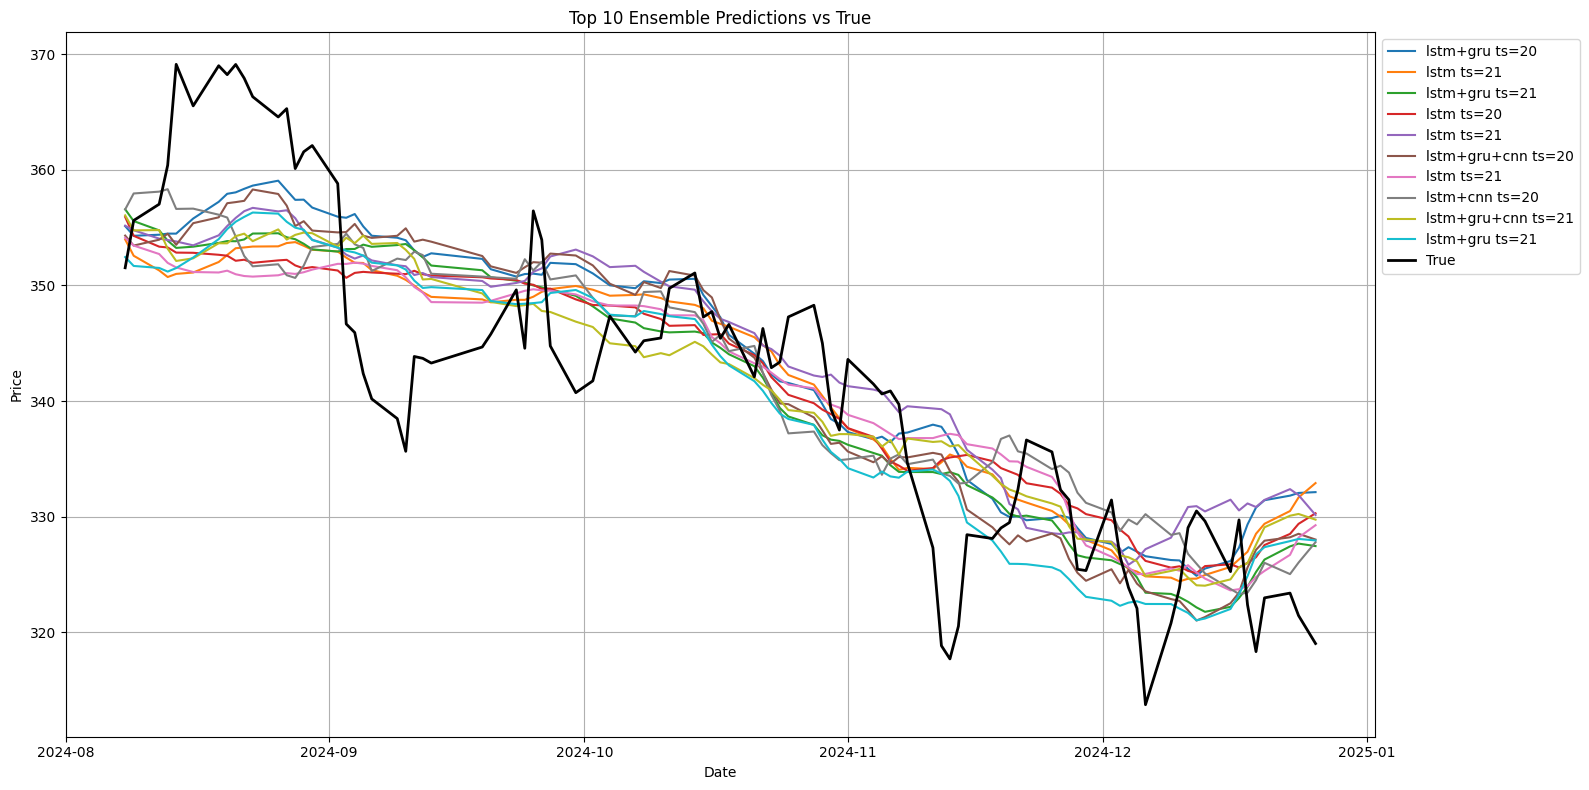

In [ ]:
import matplotlib.cm as cm

plt.figure(figsize=(16, 8))

colors = cm.get_cmap('tab10', len(top10))

for idx, (_, row) in enumerate(top10.iterrows()):
    y_true = np.array(ast.literal_eval(row['y_true']) if isinstance(row['y_true'], str) else row['y_true'])
    y_pred = np.array(ast.literal_eval(row['y_pred']) if isinstance(row['y_pred'], str) else row['y_pred'])
    dates = pd.to_datetime(ast.literal_eval(row['dates']) if isinstance(row['dates'], str) else row['dates'])

    min_len = min(len(y_true), len(y_pred), len(dates))
    y_true = y_true[:min_len]
    y_pred = y_pred[:min_len]
    dates = dates[:min_len]

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred)

    y_prev_close = np.roll(y_true, 1)
    y_prev_close[0] = y_true[0]
    y_true_direction = (y_true > y_prev_close).astype(int)
    y_pred_direction = (y_pred > y_prev_close).astype(int)
    f1 = f1_score(y_true_direction, y_pred_direction)

    print(f"{idx+1}. {row['ensemble_name']} | data_case: {row['data_case']} | time_step: {row['time_step']}")
    print(f"   RMSE: {rmse:.4f}, MAE: {mae:.4f}, R2: {r2:.4f}, MAPE: {mape:.4f}, F1: {f1:.4f}")


    plt.plot(dates, y_pred, label=f"{row['ensemble_name']} ts={row['time_step']}", color=colors(idx))

first_true = np.array(ast.literal_eval(top10.iloc[0]['y_true']) if isinstance(top10.iloc[0]['y_true'], str) else top10.iloc[0]['y_true'])
first_dates = pd.to_datetime(ast.literal_eval(top10.iloc[0]['dates']) if isinstance(top10.iloc[0]['dates'], str) else top10.iloc[0]['dates'])
min_len = min(len(first_true), len(first_dates))
plt.plot(first_dates[:min_len], first_true[:min_len], label='True', color='black', linewidth=2)

plt.xlabel("Date")
plt.ylabel("Price")
plt.title("Top 10 Ensemble Predictions vs True")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.grid(True)
plt.tight_layout()
plt.show()
